<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    LIDC IDRI: Exploration and Analysis of Pulmonary Nodules
  </h1>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    The reference dataset for lung nodule detection
  </h3>

  <p>
    LIDC IDRI is the most cited dataset in lung nodule detection and classification. It was created by seven American academic institutions, in collaboration with the <em>Foundation for the National Institutes of Health</em> and the <em>National Cancer Institute</em>.
  </p>

  <p>
    Unlike LNDb, which comes from a single institution (CHUSJ, Porto) and where each radiologist read a scan once without any consensus, LIDC IDRI was annotated by <strong>four experienced thoracic radiologists</strong> in two phases: an initial blinded read and a second unblinded read, in which each radiologist saw the anonymised marks of the other three.
  </p>

  <p>
    This notebook explores LIDC IDRI, builds its nodule table and identifies the structural differences relative to LNDb.
  </p>

</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    Setup
  </h3>

  <p>
    We import the usual libraries and <code>pylidc</code>, which reads the official LIDC XMLs and builds a local SQLite database. This is essential because the original XMLs are difficult to query directly.
  </p>

</div>

In [1]:
import numpy as np

# pylidc 0.2.3 still uses np.int, an alias removed from NumPy 1.24, so we restore only that alias.
# np.bool and np.float must not be overwritten: they exist again in NumPy 2 and the rest of NumPy relies on them.
if not hasattr(np, "int"):
    np.int = int

import pylidc as pl

/home/anasofia/labiacd/mass_detect/.venv/lib/python3.10/site-packages/pylidc/__init__.py:27: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as _pr


In [2]:
import io
from contextlib import redirect_stdout
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pylidc as pl
from sqlalchemy.orm import joinedload, selectinload

# pylidc reads ~/.pylidcrc, which must point to the folder with the DICOM files
n_scans = pl.query(pl.Scan).count()
n_patients = pl.query(pl.Scan.patient_id).distinct().count()
n_annotations = pl.query(pl.Annotation).count()
print(f"CT series:   {n_scans}")
print(f"Patients:    {n_patients}")
print(f"Annotations: {n_annotations}")

# pylidc loads the contours of each annotation with a separate query (lazy loading), which makes loops over the
# whole database very slow. This query loads everything at once (about 20 times faster).
annotations_with_contours = pl.query(pl.Annotation).options(selectinload(pl.Annotation.contours), joinedload(pl.Annotation.scan))

_clusters = {}   # the grouping of each scan is computed once and reused by the next cells
def cluster_annotations_silent(scan): # pylidc's grouping of the annotations of one scan, without its many prints
    if scan.id not in _clusters:
        with redirect_stdout(io.StringIO()):
            _clusters[scan.id] = scan.cluster_annotations()
    return _clusters[scan.id]

CT series:   1018
Patients:    1010
Annotations: 6859


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    Reading a scan with <code>pylidc</code>
  </h3>

  <p>
    Before scaling to the whole dataset, we confirm that the library works in our environment. We pick <code>LIDC IDRI 0003</code>, a scan with several nodules, which the next cells also use.
  </p>

</div>

In [3]:
patient_id = "LIDC-IDRI-0003"
scan = pl.query(pl.Scan).filter(pl.Scan.patient_id == patient_id).first()
print(f"patient_id:      {scan.patient_id}")
print(f"study_uid:       {scan.study_instance_uid[:40]}...")
print(f"series_uid:      {scan.series_instance_uid[:40]}...")
print(f"slice thickness: {scan.slice_thickness} mm")
print(f"pixel spacing:   {scan.pixel_spacing} mm")
print(f"annotations:     {len(scan.annotations)}")

patient_id:      LIDC-IDRI-0003
study_uid:       1.3.6.1.4.1.14519.5.2.1.6279.6001.101370...
series_uid:      1.3.6.1.4.1.14519.5.2.1.6279.6001.170706...
slice thickness: 2.5 mm
pixel spacing:   0.820312 mm
annotations:     13


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    Exploring Annotations
  </h3>

  <p>
    <strong>Each <code>Annotation</code> object represents one radiologist's reading of one nodule.</strong> Since each nodule was annotated by up to 4 radiologists, we have to group the annotations that refer to the <strong>same physical nodule</strong>.
  </p>

  <p>
    <code>pylidc</code> implements this through <code>scan.cluster_annotations()</code>, which returns a list of lists: each sublist contains the annotations (1 to 4) that correspond to the same nodule.
  </p>

</div>

In [4]:
clusters = scan.cluster_annotations()
print(f"Nodules: {len(clusters)} | annotations: {len(scan.annotations)}\n")
for i, cluster in enumerate(clusters):
    print(f"Nodule {i}: {len(cluster)} annotations")
    for ann in cluster:
        print(f"    id={ann.id}  malignancy={ann.malignancy}  greatest axial diameter={ann.diameter:.1f} mm")

Nodules: 4 | annotations: 13

Nodule 0: 1 annotations
    id=102  malignancy=2  greatest axial diameter=31.7 mm
Nodule 1: 4 annotations
    id=90  malignancy=5  greatest axial diameter=30.4 mm
    id=93  malignancy=5  greatest axial diameter=30.1 mm
    id=98  malignancy=3  greatest axial diameter=28.0 mm
    id=99  malignancy=4  greatest axial diameter=35.5 mm
Nodule 2: 4 annotations
    id=91  malignancy=4  greatest axial diameter=13.4 mm
    id=95  malignancy=4  greatest axial diameter=11.9 mm
    id=97  malignancy=3  greatest axial diameter=13.2 mm
    id=100  malignancy=2  greatest axial diameter=14.8 mm
Nodule 3: 4 annotations
    id=92  malignancy=4  greatest axial diameter=14.7 mm
    id=94  malignancy=5  greatest axial diameter=14.3 mm
    id=96  malignancy=3  greatest axial diameter=15.3 mm
    id=101  malignancy=2  greatest axial diameter=15.6 mm


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    The 9 subjective characteristics (per radiologist)
  </h3>

  <p>
    For each nodule ≥ 3 mm, each of the 4 thoracic radiologists subjectively evaluated the following characteristics. These are <strong>individual assessments</strong>, that is, the same nodule has 4 sets of values (one per radiologist).
  </p>

  <table style="width: 100%; border-collapse: collapse; margin-top: 15px; color: #f0f0f0;">
    <thead>
      <tr style="background-color: #c25719; color: #ffffff;">
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Characteristic</th>
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Scale</th>
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Meaning</th>
      </tr>
    </thead>
    <tbody>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>malignancy</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1 to 5</td>
        <td style="padding: 8px; border: 1px solid #444;">Overall probability of cancer</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><code>subtlety</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1 to 5</td>
        <td style="padding: 8px; border: 1px solid #444;">Difficulty in detecting the nodule</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>internalStructure</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1 to 4</td>
        <td style="padding: 8px; border: 1px solid #444;">Internal composition: soft tissue, fluid, fat or air</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><code>calcification</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1 to 6</td>
        <td style="padding: 8px; border: 1px solid #444;">Calcification pattern (1 = benign popcorn, 6 = no calcification)</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>sphericity</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1 to 5</td>
        <td style="padding: 8px; border: 1px solid #444;">Resemblance to a sphere</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><code>margin</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1 to 5</td>
        <td style="padding: 8px; border: 1px solid #444;">Sharpness of the margin</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>lobulation</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1 to 5</td>
        <td style="padding: 8px; border: 1px solid #444;">Wavy (lobulated) contour</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><code>spiculation</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1 to 5</td>
        <td style="padding: 8px; border: 1px solid #444;">Radiating spicules (sunburst sign)</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>texture</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1 to 5</td>
        <td style="padding: 8px; border: 1px solid #444;">Texture (1 = GGO, 5 = solid)</td>
      </tr>
    </tbody>
  </table>

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 25px;">
    Geometric metrics (computed by pylidc)
  </h3>

  <table style="width: 100%; border-collapse: collapse; color: #f0f0f0;">
    <thead>
      <tr style="background-color: #c25719; color: #ffffff;">
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Attribute</th>
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Unit</th>
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Meaning</th>
      </tr>
    </thead>
    <tbody>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>diameter</code></td>
        <td style="padding: 8px; border: 1px solid #444;">mm</td>
        <td style="padding: 8px; border: 1px solid #444;">Greatest diameter in the axial plane, measured on the contours</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><code>centroid</code></td>
        <td style="padding: 8px; border: 1px solid #444;">(x, y, z) in pixels</td>
        <td style="padding: 8px; border: 1px solid #444;">Nodule centroid in the volume</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>volume</code></td>
        <td style="padding: 8px; border: 1px solid #444;">mm³</td>
        <td style="padding: 8px; border: 1px solid #444;">Nodule volume (via <code>pylidc.utils.volume</code>)</td>
      </tr>
    </tbody>
  </table>

  <p style="margin-top: 20px; font-size: 0.9em; color: #cccccc;">
    <strong>Note:</strong> the subjective values are <strong>individual per radiologist assessments</strong>, not consensus values. A nodule with 4 annotations has 4 rows of characteristics, it is up to the pipeline to decide how to aggregate them.
  </p>

</div>

In [5]:
# The first annotation of the first nodule of five scans, to show how the characteristics vary in practice
examples = []
for patient in ["LIDC-IDRI-0001", "LIDC-IDRI-0003", "LIDC-IDRI-0004", "LIDC-IDRI-0005", "LIDC-IDRI-0008"]:
    one_scan = pl.query(pl.Scan).filter(pl.Scan.patient_id == patient).first()
    ann = cluster_annotations_silent(one_scan)[0][0]
    examples.append({"scan_id": patient, "diameter_mm": round(ann.diameter, 1), "malignancy": ann.malignancy,
                     "subtlety": ann.subtlety, "internalStructure": ann.internalStructure, "calcification": ann.calcification,
                     "sphericity": ann.sphericity, "margin": ann.margin, "lobulation": ann.lobulation,
                     "spiculation": ann.spiculation, "texture": ann.texture})
pd.DataFrame(examples)

,scan_id,diameter_mm,malignancy,subtlety,internalStructure,calcification,sphericity,margin,lobulation,spiculation,texture
0,LIDC-IDRI-0001,32.2,5,5,1,6,3,3,3,4,5
1,LIDC-IDRI-0003,31.7,2,1,1,6,5,2,1,1,1
2,LIDC-IDRI-0004,6.3,2,3,1,6,4,5,1,1,5
3,LIDC-IDRI-0005,6.3,3,3,1,6,4,5,1,1,5
4,LIDC-IDRI-0008,8.2,3,3,1,6,4,4,1,1,5


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    LIDC annotation categories
  </h3>

  <p>
    The original LIDC IDRI protocol distinguishes three types of finding: nodule ≥ 3 mm, nodule &lt; 3 mm, and non nodule ≥ 3 mm. <code>pylidc</code> only creates <code>Annotation</code> objects for the first category, the others exist in the original XMLs but are not loaded into the SQLite database.
  </p>

  <p>
    The 3 mm criterion of the protocol refers to the largest diameter in the axial plane, which is also what <code>pylidc</code> reports as <code>diameter</code>: the greatest axial diameter measured on the contours. The check below uses it.
  </p>

</div>

In [6]:
# Greatest axial diameter and malignancy rating of every annotation
diameters = np.array([a.diameter for a in annotations_with_contours if a.diameter is not None])
rated = sum(1 for a in annotations_with_contours if a.malignancy is not None)
print(f"LIDC series: {n_scans} | annotations available through pylidc: {n_annotations}")
print(f"Annotations with a greatest axial diameter of 3 mm or more: {(diameters >= 3).sum()} of {len(diameters)} ({(diameters >= 3).mean():.1%})")
print(f"Smallest greatest axial diameter: {diameters.min():.2f} mm")
print(f"Annotations with a malignancy rating: {rated} of {n_annotations}")

LIDC series: 1018 | annotations available through pylidc: 6859
Annotations with a greatest axial diameter of 3 mm or more: 6854 of 6859 (99.9%)
Smallest greatest axial diameter: 2.54 mm
Annotations with a malignancy rating: 6859 of 6859


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    Conclusion
  </h3>

  <p>
    <code>pylidc</code> exposes 6859 annotations across 1018 LIDC series, all with a malignancy rating. 6854 of them (99.9%) have a greatest axial diameter of 3 mm or more. The 5 below the threshold (minimum 2.54 mm) are not errors: the radiologist classified the lesion as a nodule of 3 mm or more, but the outline drawn yields a smaller greatest diameter. The foundational paper of the dataset anticipates exactly this, noting that <em>"lesions marked by a radiologist as nodule ≥ 3 mm but with outlines constructed by the radiologist that yield a greatest diameter less than 3 mm are possible"</em> (Armato et al., 2011). The annotations exposed by <code>pylidc</code> are therefore the nodules usable for classification, with no further filtering on size.
  </p>

</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h2 style="color: #c25719; margin: 0;">
    Decision: Oversized Groups

  </h2>


<h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   LIDC groups with more than four annotations
  </h3>

  <p>
    Each LIDC IDRI scan was read by four radiologists, so one physical nodule should have at most four annotations. 'pylidc' decides which annotations belong to the same nodule by joining those whose contours are closer than a tolerance. When a group ends up with more than four annotations it shrinks the tolerance by 10% and tries again, until the tolerance drops below 0.1 mm. If that still fails it returns the oversized group.
  </p>
  <p>  
    Every value in a row is computed from its group. The label is the median of the ratings, the centre is the mean of the centres and the size comes from the mean volume. If two different nodules fall in one group, the row describes something that does not exist. In the 14 affected groups (81 annotations in total):
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">the ratings alone tell us little, because about 18% of the ordinary nodules with four readers also have ratings that range by three points or more. The positions are better evidence;</li>
    <li style="margin-bottom: 8px;">in many of them the annotated centres are 13 to 38 mm apart, while the nodules have median diameters between 11 and 33 mm, so the mean centre can land on healthy tissue between two nodules and spoil every patch and radiomic feature computed later;</li>
    <li style="margin-bottom: 8px;">a few are compact and unanimous (for example five annotations that are all rated 5). Those may be a single nodule with an extra annotation. The data alone cannot tell us.</li>
  </ul>
  <p>  
    First, we considered to keep the groups and only flag them (our first version), but corrupted rows stay in the table unless every experiment remembers to filter them. Then, we also considered excluding them, but we would lose 0.5% of the rows, and these are larger than typical (the merged groups have a median diameter of about 12 mm against 6 mm overall), so we would remove a specific kind of nodule. Finally, we settled on regrouping them with a proximity rule and removing what is still too big. This choice respects the limit of four readers in every row and only discards the groups where the rule did not work.
  </p>
  <p>
    Only inside an oversized group, two annotations are joined when the distance between their centres is smaller than the larger of their two radii, with a minimum of 3 mm. This is the same criterion that the LNDb authors use to merge the readings of different radiologists in the 'joinNodules' script distributed with the dataset, and the LNDb annotation instructions were adapted from LIDC IDRI (Pedrosa et al., 2019). Using one rule for both datasets keeps their idea of "one nodule" comparable. The rule is applied only once. We tried the alternative of tightening the allowed distance step by step, as 'pylidc' does, but in several scans that cut a single annotation off a large nodule and left it as a row of its own, which probably describes no new nodule. A group that is still above four annotations after the rule is removed from the table (6 rows). Five of the six are compact (all the annotations lie within one diameter of each other), so they may be a single nodule with an extra annotation, and removing them loses some valid examples. We accept that cost to keep a table where every row respects the limit of four readers. Only one, LIDC IDRI 0055, is clearly spread out and probably holds several nodules.
  </p>
  <p>
    In an earlier test on the affected scans, the other distance metrics of 'pylidc' (maximum, average, Hausdorff) with the default tolerance split almost everything into single annotations. A proximity rule of this kind was the only one that we tested that brought every affected scan down to groups of at most four.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h2 style="color: #c25719; margin: 0;">
    Building the LIDC Table
  </h2>

</div>

In [7]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # repository root, so that `import src` works
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.mass_detect.scripts.cohort import suspicious
from src.mass_detect.scripts.config import LIDC_NODULES_FILE, READER_RATINGS_FILE
from src.mass_detect.scripts.lidc import MAX_READERS, build_lidc_table, centre_spread, describe_annotation
from src.mass_detect.scripts.lidc import import_pylidc, save_lidc_reader_ratings, split_oversized_group
from src.mass_detect.scripts.schema import SCHEMA

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
 <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   LIDC IDRI
  </h3>
  <p>
    For LIDC IDRI we do not parse the original XML files. The library 'pylidc' ships a database with every annotation already extracted, and it groups the annotations of different radiologists that refer to the same physical nodule. Each group becomes one row, and we apply the decision above to the groups that are too big. The row takes the median malignancy of its annotations (and also their mean and mode, to compare), their mean volume (and from it the equivalent diameter) and their mean centre.
  </p>
  <p>
    A few things to know:
  </p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Only nodules of 3 mm or more exist in LIDC, so there are no non nodules here. A few equivalent diameters fall slightly under 3 mm because the diameter comes from the volume of the segmentation and not from the longest axis.</li>
    <li style="margin-bottom: 8px;">World coordinates are rebuilt from the DICOM header of the first slice. They are only computed when the slices are axis aligned, and a few scans are not, so those rows have no 'x_mm' and 'y_mm'. The voxel centre ('vox_row', 'vox_col', 'vox_slice') is always kept, and that is what we will use to cut patches from LIDC.</li>
    <li style="margin-bottom: 8px;">Scanner information comes from the same header and shows how different the two datasets are.</li>
  </ol>
  <p>
    The functions that build the table live in <strong>src/mass_detect/scripts/lidc.py</strong>.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The rule of the decision above is the function split_oversized_group of lidc.py. It receives an oversized group and splits it. Two annotations are neighbours when their centres are closer than the larger of their radii (at least 3 mm), and every set of connected neighbours becomes one group. The rule is applied once. A group that is still above four annotations is removed from the table. The function centre_spread measures how spread out such a group is, to tell a nodule annotated several times from several nodules.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
 <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The rule on a real scan
  </h3>
  <p>
    Scan LIDC IDRI 0340 is one of the 14 where 'pylidc' returns a group of more than 4 annotations: it returns a single group with 8 annotations. The cell below shows those annotations (rating, centre and diameter), and then what the rule does with them. The figure draws each annotation as a circle with its real size, seen from above (the position along the scan axis is not drawn but it is in the table).
  </p>
</div>

pylidc: 1 group of 8 annotations
After the rule, group 1: 5 annotations, mean rating 3.40, spread 0.20 diameters, still above four, removed from the table
After the rule, group 2: 3 annotations, mean rating 3.00, spread 0.14 diameters


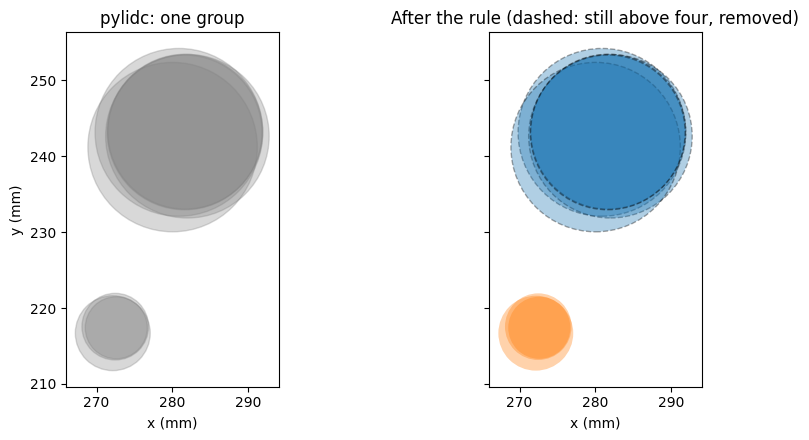

,rating,x_mm,y_mm,z_mm,diameter_mm,group_after_rule
0,4.0,280.9,243.2,-279.8,22.1,1
1,4.0,272.1,216.7,-267.6,9.9,2
2,3.0,272.6,217.4,-268.3,8.2,2
3,5.0,282.0,242.6,-280.7,21.5,1
4,2.0,280.0,241.2,-277.3,22.3,1
5,3.0,281.7,243.2,-279.5,20.4,1
6,2.0,272.5,217.6,-268.4,8.8,2
7,3.0,281.6,243.2,-279.4,20.4,1


In [8]:
def get_oversized_group(patient_id):
    """Annotations of the first group of a patient with more than four annotations, as pylidc groups them."""
    pl = import_pylidc()
    for scan in pl.query(pl.Scan).filter(pl.Scan.patient_id == patient_id).all():
        slice_positions = np.asarray(scan.slice_zvals, dtype=float)
        pixel_spacing = float(scan.pixel_spacing)
        for group in scan.cluster_annotations(verbose=False):
            if len(group) > MAX_READERS:
                return [describe_annotation(a, slice_positions, pixel_spacing) for a in group]
    raise LookupError(f"{patient_id} has no group with more than {MAX_READERS} annotations")


before = get_oversized_group("LIDC-IDRI-0340")
after = split_oversized_group(before)
group_of = {}          # annotation -> number of its group after the rule
for number, group in enumerate(after, start=1):
    for annotation in group:
        group_of[id(annotation)] = number

# The groups before and after the proximity rule
print(f"pylidc: 1 group of {len(before)} annotations")
for number, group in enumerate(after, start=1):
    mean_rating = np.mean([a["malignancy"] for a in group])
    note = ", still above four, removed from the table" if len(group) > MAX_READERS else ""
    print(f"After the rule, group {number}: {len(group)} annotations, mean rating {mean_rating:.2f}, "
          f"spread {centre_spread(group):.2f} diameters{note}")

# Each annotation as a circle in the axial plane: grey before, coloured by its new group after
fig, (ax_before, ax_after) = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
palette = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for annotation in before:
    x, y, _ = annotation["centre_mm"]
    radius = annotation["radius_mm"]
    number = group_of[id(annotation)]
    still_oversized = len(after[number - 1]) > MAX_READERS
    ax_before.add_patch(plt.Circle((x, y), radius, color="grey", alpha=0.3))
    ax_after.add_patch(plt.Circle((x, y), radius, facecolor=palette[(number - 1) % 10], alpha=0.35,
                                  edgecolor="black" if still_oversized else "none", linestyle="--"))
for axis, title in ((ax_before, "pylidc: one group"), (ax_after, "After the rule (dashed: still above four, removed)")):
    axis.set(title=title, xlabel="x (mm)", aspect="equal")
    axis.autoscale_view()
ax_before.set_ylabel("y (mm)")
plt.tight_layout()
plt.show()

pd.DataFrame({
    "rating": [a["malignancy"] for a in before],
    "x_mm": [a["centre_mm"][0] for a in before],
    "y_mm": [a["centre_mm"][1] for a in before],
    "z_mm": [a["centre_mm"][2] for a in before],
    "diameter_mm": [2 * a["radius_mm"] for a in before],
    "group_after_rule": [group_of[id(a)] for a in before],
}).round(1)

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The 8 annotations come from two different lesions, a large one of about 21 mm and a small one of about 9 mm, with their centres roughly 30 mm apart. Before the rule they would have been averaged into a single row that sits between the two lesions and mixes their ratings. After the rule the small lesion is a clean group of three annotations.
  </p>
  <p>
    The five annotations around the large lesion are more than the four radiologists can give, so that group is still above the limit. Its spread is very small (the annotations sit practically on top of each other), which points to one lesion with an extra annotation and not to several lesions. We therefore remove it from the table, accepting that it is probably a valid nodule, so that no row exceeds four annotations.
  </p>
  <p>
    Now the main function. For every scan it asks 'pylidc' for its default groups. Any group with more than four annotations is passed to the rule above. We test that condition directly instead of relying on the message that `pylidc` prints, and at the end we list the scans where `pylidc` did not get to a conclusion, so the problem is never hidden.
  </p>
</div>

In [9]:
# One row per LIDC nodule, built from the pylidc annotations (about 4 minutes)
lidc = build_lidc_table()

# Remove the groups that the proximity rule could not bring down to four annotations
oversized = lidc["oversized_group"].astype(bool)
removed = lidc[oversized]
lidc = lidc[~oversized].reset_index(drop=True)
print(f"Removed {len(removed)} groups still above four annotations: {sorted(removed['patient_id'].unique())}")

print(f"{len(lidc)} nodules in {lidc['patient_id'].nunique()} patients ({lidc['scan_id'].nunique()} CT series)")
print("Annotations per nodule:", lidc["n_readings"].value_counts().sort_index().to_dict())
print(f"Rows produced by the proximity rule: {lidc['reclustered'].sum()}")
print(f"Nodules without world x and y (slices not axis aligned): {lidc['x_mm'].isna().sum()}")

0/1018 scans


200/1018 scans


400/1018 scans


600/1018 scans


800/1018 scans


pylidc could not keep every group at four annotations or fewer in 14 scans: ['LIDC-IDRI-0055', 'LIDC-IDRI-0092', 'LIDC-IDRI-0137', 'LIDC-IDRI-0204', 'LIDC-IDRI-0252', 'LIDC-IDRI-0332', 'LIDC-IDRI-0340', 'LIDC-IDRI-0366', 'LIDC-IDRI-0404', 'LIDC-IDRI-0608', 'LIDC-IDRI-0815', 'LIDC-IDRI-0863', 'LIDC-IDRI-0865', 'LIDC-IDRI-0942']
After applying the rule once, 6 groups still have more than four annotations. They are flagged in oversized_group and removed in notebook 02:
  LIDC-IDRI-0055: 6 annotations, ratings [2.0, 2.0, 3.0, 4.0, 4.0, 4.0], spread 1.52 diameters
  LIDC-IDRI-0092: 5 annotations, ratings [2.0, 2.0, 3.0, 3.0, 3.0], spread 0.7 diameters
  LIDC-IDRI-0204: 5 annotations, ratings [3.0, 4.0, 4.0, 5.0, 5.0], spread 0.85 diameters
  LIDC-IDRI-0340: 5 annotations, ratings [2.0, 3.0, 3.0, 4.0, 5.0], spread 0.2 diameters
  LIDC-IDRI-0863: 5 annotations, ratings [1.0, 1.0, 1.0, 1.0, 1.0], spread 0.8 diameters
  LIDC-IDRI-0865: 5 annotations, ratings [5.0, 5.0, 5.0, 5.0, 5.0], spread 0.

Removed 6 groups still above four annotations: ['LIDC-IDRI-0055', 'LIDC-IDRI-0092', 'LIDC-IDRI-0204', 'LIDC-IDRI-0340', 'LIDC-IDRI-0863', 'LIDC-IDRI-0865']
2657 nodules in 874 patients (882 CT series)
Annotations per nodule: {1: 779, 2: 488, 3: 487, 4: 903}
Rows produced by the proximity rule: 20
Nodules without world x and y (slices not axis aligned): 36


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    To ensure the correction did what we expected, we compare with the counts that Armato et al. (2011) reports for the whole database. The numbers will not match exactly, because the database version and the counting rules are not necessarily the same.
  </p>
</div>

In [10]:
check = pd.DataFrame({
    "nodules of 3 mm or more": [2669, 2651, len(lidc)],
    "nodules with all four readers": [928, 897, int((lidc["n_readings"] == 4).sum())],
}, index=["Armato et al. (2011)", "our first version", "this version"])
check

,nodules of 3 mm or more,nodules with all four readers
Armato et al. (2011),2669,928
our first version,2651,897
this version,2657,903


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  The 14 groups where ‘pylidc’ did not produce a conclusion became 26 rows, and 6 of them still had more than four annotations. These 6 rows were removed from the table, so every remaining row respects the limit of four readers.
  </p>
  <p>
    The LIDC table has 2657 nodules from 874 patients, 12 below the 2669 reported by Armato et al. The number of nodules with four readers is 903, still 25 below the 928 reported. Since the database versions and the counting rules can differ and our rule is an heuristic this comparison is not meant to be exactly the same. The comparison is a sanity check and not a validation: it tells us that we are in the right range and that the correction does not distort the totals.
  </p>
  <p>
    Of the six removed groups, five are compact (their annotations lie within one diameter of each other), which fits a single nodule with an extra annotation. LIDC IDRI 0055, with a spread of 1.52 diameters, is the one that probably holds several nodules. The loss is small (6 of 2663 nodules).
  </p>
</div>

In [11]:
lidc.to_csv(LIDC_NODULES_FILE, index=False)
print(f"saved {lidc.shape} to {LIDC_NODULES_FILE.name}")

saved (2657, 31) to lidc_nodules.csv


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    How many radiologists annotated each nodule?
  </h3>

  <p>
    Each row of the table merges the annotations of one nodule, so their number tells us how many of the four radiologists found and rated it. In LIDC IDRI every annotation carries a malignancy rating, so the number of annotations is also the number of ratings.
  </p>

</div>

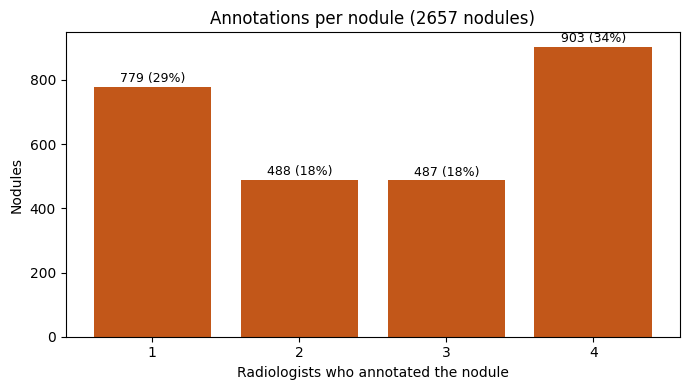

Read by a single radiologist: 29% | by all four: 903


In [12]:
readers = lidc["n_readings"].value_counts().sort_index()
assert (lidc["n_rated"] == lidc["n_readings"]).all()      # every annotation has a malignancy rating

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(readers.index, readers.values, color="#c25719")
for bar, n in zip(bars, readers.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 15, f"{n} ({n / len(lidc):.0%})", ha="center", fontsize=9)
ax.set_xticks(readers.index)
ax.set_xlabel("Radiologists who annotated the nodule")
ax.set_ylabel("Nodules")
ax.set_title(f"Annotations per nodule ({len(lidc)} nodules)")
plt.tight_layout()
plt.show()
print(f"Read by a single radiologist: {(lidc['n_readings'] == 1).mean():.0%} | by all four: {(lidc['n_readings'] == 4).sum()}")

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    Conclusion
  </h3>

  <p>
    779 nodules (29%) were annotated by a single radiologist, 488 by two, 487 by three and 903 by all four. Only the 1878 nodules with two or more annotations allow us to measure agreement, which is the next section.
  </p>

</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    Agreement between radiologists in LIDC
  </h3>

  <p>
    In LIDC, each nodule was annotated by up to 4 radiologists in two phases (one blinded and one unblinded), so the same physical nodule typically has several malignancy assessments, one per radiologist.
  </p>

  <p>
    If these assessments always agreed, aggregation would be trivial. They do not. This section quantifies the disagreement along two dimensions:
  </p>

  <ol style="padding-left: 20px;">
    <li style="margin-bottom: 6px;"><strong>Amplitude</strong>, the difference between the highest and the lowest rating a nodule received (<code>highest minus lowest</code>), on the 0 to 4 range.</li>
    <li style="margin-bottom: 6px;"><strong>Severity</strong>, whether the disagreement is just scale noise (one point difference) or whether it is clinical, that is, whether one radiologist classified the nodule as benign (1 to 2) and another as malignant (4 to 5).</li>
  </ol>

  <p>
    The goal is to measure the intrinsic label noise before deciding how to aggregate it, following the same logic applied to LNDb.
  </p>

</div>

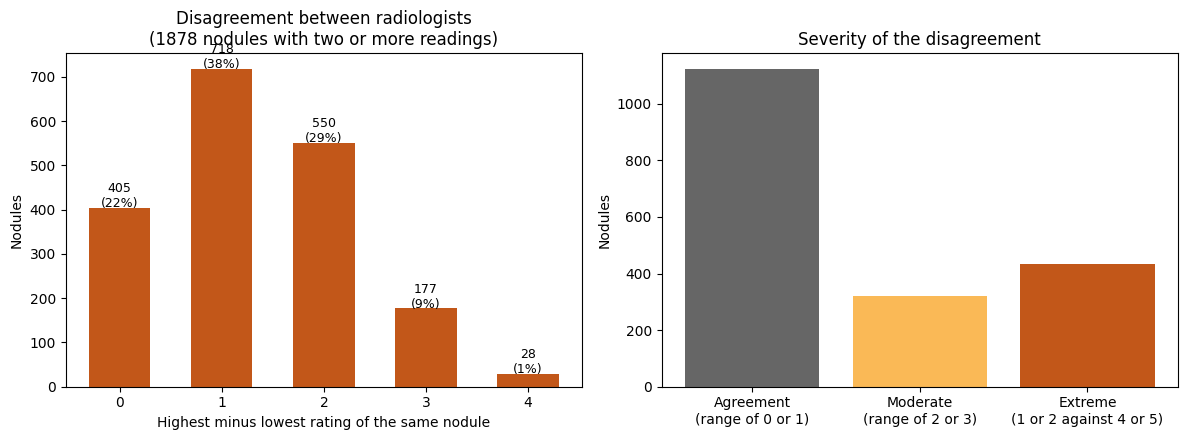

1878 nodules with two or more readings
Same rating from everyone: 405 (22%)
One point apart: 718 (38%)
Two points or more apart: 755 (40%)
Benign for one reader and suspicious for another: 435 (23%)


In [13]:
# Spread of the ratings of every nodule read by two or more radiologists
multi = lidc[lidc["n_rated"] >= 2].copy()
multi["range"] = (multi["mal_max"] - multi["mal_min"]).astype(int)
extreme = (multi["mal_min"] <= 2) & (multi["mal_max"] >= 4)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
counts = multi["range"].value_counts().reindex(range(5), fill_value=0)
axes[0].bar(counts.index, counts.values, width=0.6, color="#c25719")
for x, n in zip(counts.index, counts.values):
    axes[0].text(x, n + 2, f"{n}\n({n / len(multi):.0%})", ha="center", fontsize=9)
axes[0].set_xlabel("Highest minus lowest rating of the same nodule")
axes[0].set_ylabel("Nodules")
axes[0].set_title(f"Disagreement between radiologists\n({len(multi)} nodules with two or more readings)")
axes[1].bar(["Agreement\n(range of 0 or 1)", "Moderate\n(range of 2 or 3)", "Extreme\n(1 or 2 against 4 or 5)"],
            [(multi["range"] <= 1).sum(), ((multi["range"] >= 2) & ~extreme).sum(), extreme.sum()],
            color=["#666666", "#fab956", "#c25719"])
axes[1].set_ylabel("Nodules")
axes[1].set_title("Severity of the disagreement")
plt.tight_layout()
plt.show()

print(f"{len(multi)} nodules with two or more readings")
print(f"Same rating from everyone: {(multi['range'] == 0).sum()} ({(multi['range'] == 0).mean():.0%})")
print(f"One point apart: {(multi['range'] == 1).sum()} ({(multi['range'] == 1).mean():.0%})")
print(f"Two points or more apart: {(multi['range'] >= 2).sum()} ({(multi['range'] >= 2).mean():.0%})")
print(f"Benign for one reader and suspicious for another: {extreme.sum()} ({extreme.mean():.0%})")

In [14]:
# How the three rules that combine the readers change the label (each rounded half up), by number of readers
labels = pd.DataFrame({rule: np.floor(lidc[f"mal_{rule}"] + 0.5).astype(int) for rule in ["median", "mean", "mode"]})
rating_of = {a.id: a.malignancy for a in annotations_with_contours}      # the rating of every annotation

def has_tie(annotation_ids): # True when two or more ratings of the nodule are the most frequent ones
    ratings = [rating_of[int(i)] for i in annotation_ids.split(";")]
    counts = np.unique(ratings, return_counts=True)[1]
    return np.sum(counts == counts.max()) > 1

readers = lidc["n_rated"].rename("readers")
by_readers = pd.DataFrame({
    "nodules": readers.value_counts().sort_index(),
    "tie for the mode": lidc["annotation_ids"].map(has_tie).groupby(readers).sum(),
    "mean differs from the median": (labels["mean"] != labels["median"]).groupby(readers).sum(),
    "mode differs from the median": (labels["mode"] != labels["median"]).groupby(readers).sum(),
})
display(by_readers)

# Nodules of each rating with each rule, and on the binary scale
per_rating = labels.apply(lambda label: label.value_counts()).reindex(range(1, 6)).T
per_rating["suspicious (4 or 5)"] = labels.apply(lambda label: suspicious(label).sum())
display(per_rating)

# Where the labels move: rows are the label given by the mean or by the mode, columns the label given by the median
display(pd.crosstab(labels["mean"], labels["median"], rownames=["mean"], colnames=["median"]))
display(pd.crosstab(labels["mode"], labels["median"], rownames=["mode"], colnames=["median"]))

,nodules,tie for the mode,mean differs from the median,mode differs from the median
readers,,,,
1,779,0,0,0
2,488,279,0,0
3,487,88,75,0
4,903,189,178,79


,1,2,3,4,5,suspicious (4 or 5)
median,323,552,1233,360,189,549
mean,286,609,1255,394,113,507
mode,332,579,1218,326,202,528


median,1,2,3,4,5
mean,,,,,
1,286,0,0,0,0
2,37,535,37,0,0
3,0,17,1174,64,0
4,0,0,22,296,76
5,0,0,0,0,113


median,1,2,3,4,5
mode,,,,,
1,323,7,2,0,0
2,0,545,34,0,0
3,0,0,1196,22,0
4,0,0,1,325,0
5,0,0,0,13,189


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    Conclusion
  </h3>

  <p>
    Of the 1878 LIDC nodules with two or more readings, only 405 (22%) show perfect agreement between radiologists. Another 718 (38%) differ by a single point, which on a five value ordinal scale is close to noise. The remaining 755 (40%) differ by two points or more, substantial disagreement.
  </p>

  <p>
    The most relevant number is that of extreme disagreement: 435 nodules (23%) were classified as benign (1 to 2) by one radiologist and as malignant (4 to 5) by another.
  </p>

  <p>
    <strong>Implications for the pipeline:</strong> the magnitude of the disagreement justifies three decisions. First, aggregate per nodule instead of choosing an arbitrary reading, otherwise the label would depend on which radiologist happened to be recorded first. Second, combine the ratings with a rule that a single dissenting reader cannot move, which is the case of the median, and not with the maximum, which would amplify the spread. Third, keep the nodules on which the readers disagree instead of discarding them, because disagreement between radiologists does not only affect label confidence, it affects the very definition of "benign" and "malignant" for borderline cases, and those are the cases a model meets in practice.
  </p>

  <p>
    <strong>How the rule that combines the readers changes the label.</strong> The table below compares the median, which is our label, with the mean and the mode (where a tie between ratings gives the median of the tied ratings). With one reader the three rules agree. With two readers the median equals the mean, and the mode exists only when both agree; in the 279 nodules where they disagree, the tie rule gives the median again. With three readers the mode, when it exists, is the rating shared by two readers, which is also the median, and the 88 nodules with three different ratings get the median through the tie rule. The mode can therefore differ from the median only with four readers, and it does on 79 of the 903 nodules, those where two readers agree and the other two split (1, 1, 3 and 4 give a mode of 1 and a median of 2).
  </p>

  <p>
    The mean differs from the median on 253 nodules, 75 read by three radiologists and 178 by four, because one dissenting reader pulls the mean towards the middle. The median moves those nodules away from 3 in both directions: 37 nodules that the mean rates 2 are rated 1 by the median, and 76 that the mean rates 4 are rated 5. The ends of the scale grow: 189 nodules are rated 5 with the median against 113 with the mean, and 549 are suspicious (4 or 5) against 507. Notebook 06 checks whether these differences make the label easier or harder to learn.
  </p>

</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    Visualising a Nodule
  </h3>

  <p>
    We visually confirm that the centroids and masks correspond to real nodules.
  </p>

</div>

Loading dicom files ... This may take a moment.


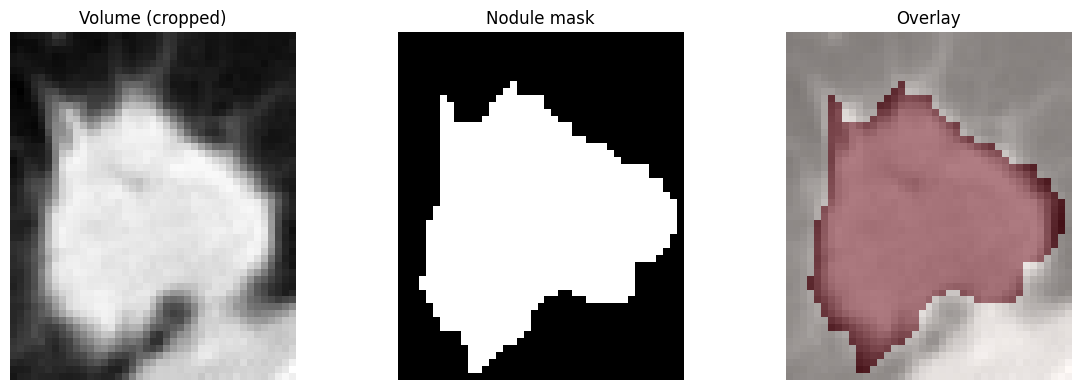

Greatest axial diameter: 32.21 mm | malignancy: 5 | texture: 5


In [15]:
# One annotation drawn by pylidc: the cropped CT, the mask of the radiologist and both together
scan = pl.query(pl.Scan).filter(pl.Scan.patient_id == "LIDC-IDRI-0001").first()
ann = cluster_annotations_silent(scan)[0][0]         # first annotation of the first nodule
cropped = scan.to_volume()[ann.bbox()]
mask = ann.boolean_mask()
middle = cropped.shape[2] // 2

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(cropped[:, :, middle], cmap="gray")
axes[0].set_title("Volume (cropped)")
axes[1].imshow(mask[:, :, middle], cmap="gray")
axes[1].set_title("Nodule mask")
axes[2].imshow(cropped[:, :, middle], cmap="gray")
axes[2].imshow(mask[:, :, middle], cmap="Reds", alpha=0.5)
axes[2].set_title("Overlay")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()
print(f"Greatest axial diameter: {ann.diameter:.2f} mm | malignancy: {ann.malignancy} | texture: {ann.texture}")

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    Nodule diameter distribution
  </h3>

  <p>
    For each nodule the table holds the equivalent diameter: the diameter of a sphere with the mean volume of its annotations. Unlike the greatest axial diameter of each annotation used above, it describes the nodule as a whole, and it is computed in the same way as in LNDb.
  </p>

</div>

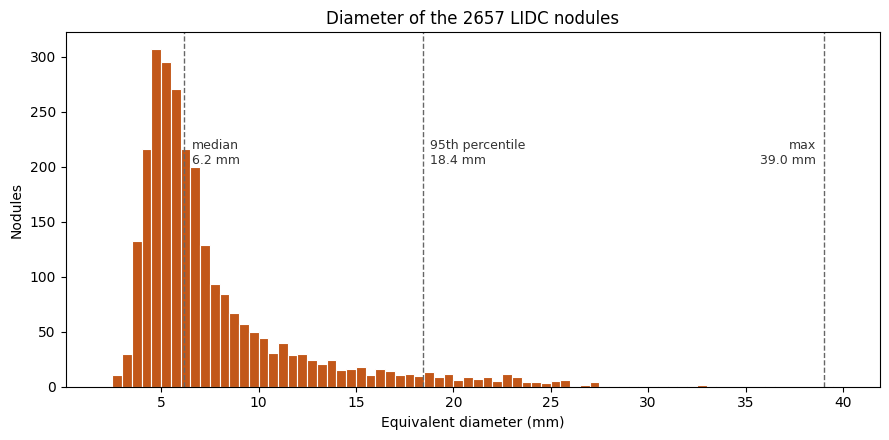

under 3 mm: 11 | above 20 mm: 98


count    2657.00
mean        7.76
std         4.65
min         2.54
50%         6.16
95%        18.42
99%        25.16
max        39.02
Name: diameter_mm, dtype: float64

In [16]:
diameters = lidc["diameter_mm"]
p50, p95, dmax = diameters.median(), diameters.quantile(0.95), diameters.max()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(diameters, bins=np.arange(2, diameters.max() + 1, 0.5), color="#c25719", edgecolor="white", linewidth=0.8)
top = ax.get_ylim()[1]
for value, name, align in [(p50, "median", "left"), (p95, "95th percentile", "left"), (dmax, "max", "right")]:
    ax.axvline(value, color="#666666", linestyle="--", linewidth=1)
    offset = 0.4 if align == "left" else -0.4
    ax.text(value + offset, top * 0.7, f"{name}\n{value:.1f} mm", ha=align, va="top", fontsize=9, color="#333333")
ax.set_xlabel("Equivalent diameter (mm)")
ax.set_ylabel("Nodules")
ax.set_title(f"Diameter of the {len(lidc)} LIDC nodules")
plt.tight_layout()
plt.show()
print(f"under 3 mm: {(diameters < 3).sum()} | above 20 mm: {(diameters > 20).sum()}")
diameters.describe(percentiles=[0.5, 0.95, 0.99]).round(2)

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    Conclusion
  </h3>

  <p>
    The equivalent diameter of the 2657 nodules has a median of 6.16 mm, a 95th percentile of 18.42 mm and a maximum of 39.02 mm. The distribution is strongly skewed to the right: most nodules are small, with a long tail of large ones, and 98 are above 20 mm. 11 nodules have an equivalent diameter under 3 mm: a flat or elongated nodule can reach 3 mm in its greatest axial diameter and still have a smaller equivalent sphere. The largest single annotation reaches 61.58 mm of greatest axial diameter, but that is the outline of one reader, not a nodule of the table.
  </p>

  <p>
    This distribution has two implications for the pipeline:
  </p>

  <p>
    <strong>Patch size.</strong> What has to fit in the patch is the region the models use, the consensus of the readers. Notebook 05 measures it: a 64 mm cube cuts no consensus region, while a 30 mm cube would cut 107 LIDC IDRI regions and a 51 mm cube 4. We therefore use the same 64 mm cube in both datasets.
  </p>

  <p>
    <strong>Need for resampling.</strong> Since the diameter is in millimetres but the images have variable in plane spacing (typically 0.5 to 0.8 mm), any comparison between nodules from different scans requires resampling to isotropic spacing.
  </p>

</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    EDA, Voxel spacing between scans
  </h3>

  <p>
    LIDC was acquired at 7 institutions with different scanners, unlike LNDb (1 institution, 3 Siemens models). The heterogeneity of spacing is the main reason why resampling before feature extraction makes sense.
  </p>

  <p>
    <strong>What this decides:</strong> whether it is worth resampling to isotropic spacing, and to which value. The answer for LNDb was already "yes". Here we want to see whether LIDC allows the same target.
  </p>

</div>

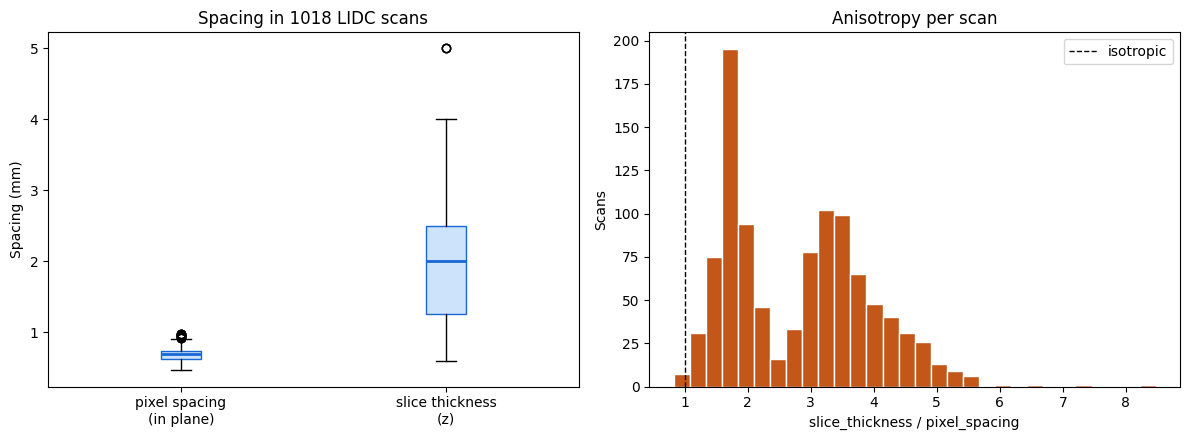

       pixel_spacing  slice_thickness  anisotropy
count       1018.000         1018.000    1018.000
mean           0.688            1.919       2.821
std            0.085            0.729       1.122
min            0.461            0.600       0.821
25%            0.625            1.250       1.778
50%            0.699            2.000       2.917
75%            0.742            2.500       3.556
max            0.977            5.000       8.477

Isotropic scans (ratio between 0.95 and 1.05): 2


In [17]:
# Spacing of every scan, and its anisotropy (slice thickness over pixel spacing)
spacings = []
for scan in pl.query(pl.Scan):
    spacings.append({"patient_id": scan.patient_id,
                     "slice_thickness": scan.slice_thickness,
                     "pixel_spacing": scan.pixel_spacing})
df_spacing = pd.DataFrame(spacings)
df_spacing["anisotropy"] = df_spacing["slice_thickness"] / df_spacing["pixel_spacing"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].boxplot([df_spacing["pixel_spacing"].dropna(), df_spacing["slice_thickness"].dropna()],
                tick_labels=["pixel spacing\n(in plane)", "slice thickness\n(z)"],
                patch_artist=True,
                boxprops=dict(facecolor="#cde2fb", edgecolor="#1967d2"),
                medianprops=dict(color="#1967d2", linewidth=2))
axes[0].set_ylabel("Spacing (mm)")
axes[0].set_title(f"Spacing in {len(df_spacing)} LIDC scans")

axes[1].hist(df_spacing["anisotropy"].dropna(), bins=30, color="#c25719", edgecolor="white")
axes[1].axvline(1.0, color="black", linestyle="--", linewidth=1, label="isotropic")
axes[1].set_xlabel("slice_thickness / pixel_spacing")
axes[1].set_ylabel("Scans")
axes[1].set_title("Anisotropy per scan")
axes[1].legend()
plt.tight_layout()
plt.show()

print(df_spacing[["pixel_spacing", "slice_thickness", "anisotropy"]].describe().round(3))
isotropic = df_spacing["anisotropy"].between(0.95, 1.05, inclusive="neither")
print(f"\nIsotropic scans (ratio between 0.95 and 1.05): {isotropic.sum()}")

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    Conclusion
  </h3>

  <p>
    The 1018 LIDC scans have a median in plane spacing of 0.70 mm (IQR 0.63 to 0.74 mm) and a median slice thickness of 2.00 mm (IQR 1.25 to 2.50 mm), with values up to 5.00 mm. The ratio between slice thickness and pixel spacing has a median of 2.92, and only 2 of the 1018 scans are isotropic. That is, in almost every scan, a voxel is about three times taller than it is wide, and the physical distance between neighbours along z is three times the in plane distance.
  </p>

  <p>
    <strong>Implications for the pipeline:</strong>
  </p>

  <p>
    <strong>Resampling is necessary.</strong> 3D texture features (GLCM, GLRLM and similar) compare neighbouring voxels assuming they are at the same physical distance in all directions. In an anisotropic volume, that assumption is false, and the features mix different scales. The recommendation of the <em>Image Biomarker Standardisation Initiative</em> is to resample to a common isotropic spacing before feature extraction, to guarantee comparability across scans and rotational invariance of 3D features (Zwanenburg et al., 2020). It does not prescribe the size of the voxel.
  </p>

  <p>
    <strong>We use 0.6 mm.</strong> A voxel close to the in plane spacing keeps the in plane detail, but along z it only interpolates: the median LIDC slice is 2 mm, so a fine grid places several grid slices on every real one, and the features depend more on the slice thickness. Notebook 05 measures both sides with a sensitivity analysis at 0.6, 1, 1.5 and 2 mm. 0.6 mm predicts best and keeps every small nodule, at the cost of a stronger dependence on the slice thickness (39% of the features against 33% at 1 mm), which notebook 06 addresses when it compares ways of pooling the datasets.
  </p>

  <p>
    <strong>Note on the limitations of resampling.</strong> Recent studies show that isotropic resampling alone does not completely eliminate the effect of slice thickness variation on radiomic features (Yang et al., 2021; Peoples et al., 2025). An alternative that has been proposed is to extract features directly from the native images, incorporating the physical voxel dimensions into the calculation, without interpolation (Corral Fontecha et al., 2026). This approach preserves the original signal but is outside the scope of this work; resampling remains the established standard and the one that allows direct comparability with the existing literature.
  </p>

</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    Malignancy distribution per nodule
  </h3>

  <p>
    Counting annotations overcounts: a nodule read by four radiologists contributes four times, even though it is a single nodule, so the classes that radiologists use most often look bigger than they are.
  </p>

  <p>
    We therefore count per nodule, with the label that the models use: the median of the ratings rounded half up, so 2.5 becomes 3, as in LNDb (notebook 00 explains why). The binary scale is derived from that rating: ratings 4 and 5 are suspicious, ratings 1 to 3 are not.
  </p>

</div>

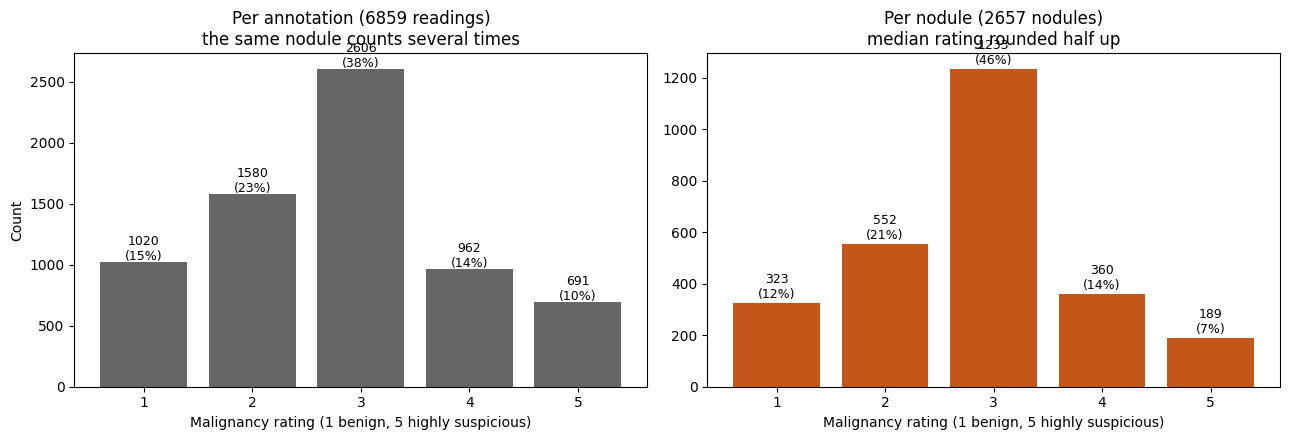

Suspicious: 549 of 2657 nodules (21%)


In [18]:
# Ratings counted per annotation (one per radiologist) and per nodule (the label)
annotation_ratings = pd.Series([a.malignancy for a in annotations_with_contours])
per_annotation = annotation_ratings.value_counts().reindex(range(1, 6), fill_value=0)
rating = np.floor(lidc["mal_median"] + 0.5).astype(int)                   # the median, half up: 2.5 becomes 3
per_nodule = rating.value_counts().reindex(range(1, 6), fill_value=0)

panels = [
    (per_annotation, "#666666", f"Per annotation ({per_annotation.sum()} readings)\nthe same nodule counts several times"),
    (per_nodule, "#c25719", f"Per nodule ({len(lidc)} nodules)\nmedian rating rounded half up"),
]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for axis, (counts, colour, title) in zip(axes, panels):
    bars = axis.bar(counts.index, counts.values, color=colour)
    for bar, n in zip(bars, counts.values):
        axis.text(bar.get_x() + bar.get_width() / 2, n + 20, f"{n}\n({n / counts.sum():.0%})", ha="center", fontsize=9)
    axis.set_xticks(range(1, 6))
    axis.set_xlabel("Malignancy rating (1 benign, 5 highly suspicious)")
    axis.set_title(title)
axes[0].set_ylabel("Count")
plt.tight_layout()
plt.show()

# The binary scale: suspicious for ratings 4 and 5, not suspicious for ratings 1 to 3
positive = suspicious(rating)
print(f"Suspicious: {positive.sum()} of {len(rating)} nodules ({positive.mean():.0%})")

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    Conclusion
  </h3>

  <p>
    Per nodule, 323 nodules (12%) are rated 1, 552 (21%) are rated 2, 1233 (46%) are rated 3, 360 (14%) are rated 4 and 189 (7%) are rated 5. On the binary scale this gives 549 suspicious nodules (21%) and 2108 not suspicious.
  </p>

  <p>
    <strong>The central observation is the size of the indeterminate class.</strong> Almost half of the LIDC IDRI nodules are rated 3, against 33% of the LNDb nodules with a mask. There are two reasons. LIDC IDRI has up to four readers per nodule, against one or two in most LNDb nodules, and combining readers who disagree pulls a nodule towards the middle: the median resists a single dissenting reader, but two readings of 2 and 4, or of 1 and 5, still give 3. A large part of the indeterminate class therefore reflects disagreement between readers rather than a nodule that each reader finds indeterminate.
  </p>

  <p>
    <strong>Implications for the pipeline.</strong> Discarding the indeterminate class would cost almost half of the LIDC IDRI nodules so the class is kept; on the binary scale these nodules count as not suspicious. The suspicious class is also larger here (21%) than in the LNDb cohort (14%). The two datasets therefore have different label distributions, and notebook 06 compares ways of pooling them that take this into account.
  </p>

</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    Acquisition parameters
  </h3>

  <p>
    LNDb is homogeneous (one institution, 3 Siemens models). LIDC is not: 7 institutions, several manufacturers, several protocols. This affects the intensity distribution of the images and, consequently, the extracted features.
  </p>

  <p>
    <strong>What this decides:</strong> how intensities are handled across scanners, and whether the scanner should enter the model as a feature or only be used to check it.
  </p>

</div>

Scans with DICOM files: 1018 | without: 0


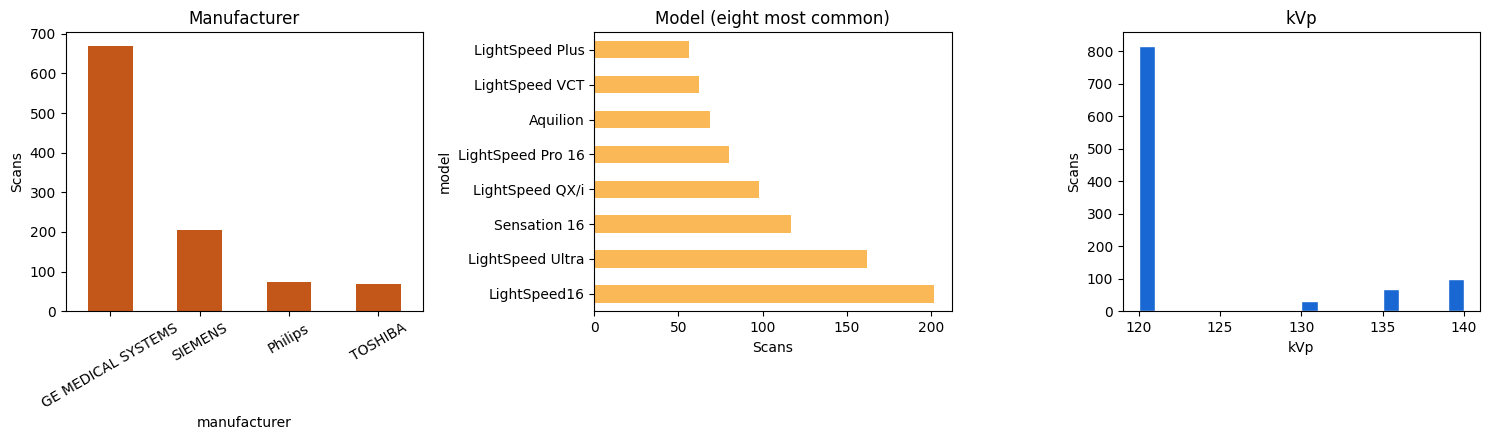

kVp: min=120, median=120, max=140


In [19]:
import pydicom

ACQUISITION_TAGS = {"manufacturer": "Manufacturer", "model": "ManufacturerModelName", "kvp": "KVP",
                    "exposure": "Exposure", "convolution_kernel": "ConvolutionKernel", "institution_name": "InstitutionName"}

def read_acquisition(scan):
    """Header of the first DICOM file of the scan; None when the folder is missing or empty."""
    try:
        dicom_dir = Path(scan.get_path_to_dicom_files())
    except Exception:
        return None
    # skip the macOS '._' copies, which are not DICOM files
    dcm_files = sorted(f for f in dicom_dir.glob("*.dcm") if not f.name.startswith("._"))
    if not dcm_files:
        return None
    header = pydicom.dcmread(str(dcm_files[0]), stop_before_pixels=True)
    result = {"patient_id": scan.patient_id}
    for column, tag in ACQUISITION_TAGS.items():
        value = getattr(header, tag, None)
        if isinstance(value, (list, tuple)):
            value = str(value[0]) if len(value) > 0 else None
        result[column] = value
    return result

# Every scan; the ones without DICOM files are counted and skipped
acquisition, without_dicom = [], 0
for scan in pl.query(pl.Scan):
    meta = read_acquisition(scan)
    if meta is None:
        without_dicom += 1
    else:
        acquisition.append(meta)
df_aq = pd.DataFrame(acquisition)
print(f"Scans with DICOM files: {len(df_aq)} | without: {without_dicom}")

# Manufacturer, model and tube voltage
kvp_vals = pd.to_numeric(df_aq["kvp"], errors="coerce").dropna()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
df_aq["manufacturer"].dropna().value_counts().plot(kind="bar", ax=axes[0], color="#c25719")
axes[0].set_title("Manufacturer")
axes[0].set_ylabel("Scans")
axes[0].tick_params(axis="x", rotation=30)
df_aq["model"].dropna().value_counts().head(8).plot(kind="barh", ax=axes[1], color="#fab956")
axes[1].set_title("Model (eight most common)")
axes[1].set_xlabel("Scans")
axes[2].hist(kvp_vals, bins=20, color="#1967d2", edgecolor="white")
axes[2].set_title("kVp")
axes[2].set_xlabel("kVp")
axes[2].set_ylabel("Scans")
plt.tight_layout()
plt.show()
print(f"kVp: min={kvp_vals.min():.0f}, median={kvp_vals.median():.0f}, max={kvp_vals.max():.0f}")

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    Conclusion
  </h3>

  <p>
    The acquisition metadata shows the heterogeneity of LIDC IDRI. The 1018 scans come from several manufacturers and scanner models, and the tube voltage varies between 120 and 140 kVp, with a median of 120. LNDb is very different: a single institution and three Siemens models.
  </p>

  <p>
    <strong>Implications for the pipeline:</strong>
  </p>

  <p>
    <strong>Intensities stay in Hounsfield units.</strong> HU are a calibrated physical scale, the same in every scanner, so we do not rescale each scan. Intensities are clipped to [-1024, 3071] HU and discretised with a fixed bin width of 25 HU (notebook 05), as the IBSI recommends for calibrated units. What changes between scanners is the reconstruction kernel and the slice thickness, which affect texture. Notebook 05 measures how much the features depend on the slice thickness, and notebook 06 compares harmonisation (ComBat) with plain pooling.
  </p>

  <p>
    <strong>Manufacturer and model do not enter the model as features.</strong> Used directly, they would let the model take a shortcut through scanner specific patterns that say nothing about the nodule.
  </p>

  <p>
    <strong>They are used to check the model.</strong> Scanner, kernel and slice thickness define the subgroups on which notebook 06 checks that the model works equally well. Validation is grouped by patient, and both LNDb and LIDC IDRI are validated, so the gap between the two datasets is measured directly.
  </p>

</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    Decision, Mask consensus
  </h3>

  <p>
    LNDb has one 3D mask per nodule per radiologist, precomputed. LIDC has no mask files: it has XML contours that pylidc reconstructs in memory. When a nodule has more than one radiologist, we have to <strong>decide how to produce a single mask per nodule</strong>, because the classifier cannot train on 4 different masks for the same nodule.
  </p>

  <p>
    Three possible options:
  </p>

  <table style="width: 100%; border-collapse: collapse; margin-top: 15px; color: #f0f0f0;">
    <thead>
      <tr style="background-color: #c25719; color: #ffffff;">
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Method</th>
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Rule</th>
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Advantage</th>
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Disadvantage</th>
      </tr>
    </thead>
    <tbody>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><strong>Union</strong></td>
        <td style="padding: 8px; border: 1px solid #444;">voxel positive if ≥1 radiologist marked it</td>
        <td style="padding: 8px; border: 1px solid #444;">preserves the whole nodule</td>
        <td style="padding: 8px; border: 1px solid #444;">overestimates the volume, includes normal tissue</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><strong>Intersection</strong></td>
        <td style="padding: 8px; border: 1px solid #444;">voxel positive if all marked it</td>
        <td style="padding: 8px; border: 1px solid #444;">conservative</td>
        <td style="padding: 8px; border: 1px solid #444;">mask may end up empty</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><strong>At least half</strong></td>
        <td style="padding: 8px; border: 1px solid #444;">voxel positive if 50% or more marked it</td>
        <td style="padding: 8px; border: 1px solid #444;">balance, literature default</td>
        <td style="padding: 8px; border: 1px solid #444;">needs ≥2 radiologists</td>
      </tr>
    </tbody>
  </table>

  <p style="margin-top: 20px;">
    <strong>Decision taken:</strong> at least half of the radiologists, the rule of <code>pylidc.utils.consensus()</code> with <code>clevel=0.5</code>, because it is the literature default and keeps what most radiologists agree on when there is disagreement. Nodules with a single radiologist keep that radiologist's mask (there is no consensus to compute).
  </p>

</div>

Loading dicom files ... This may take a moment.


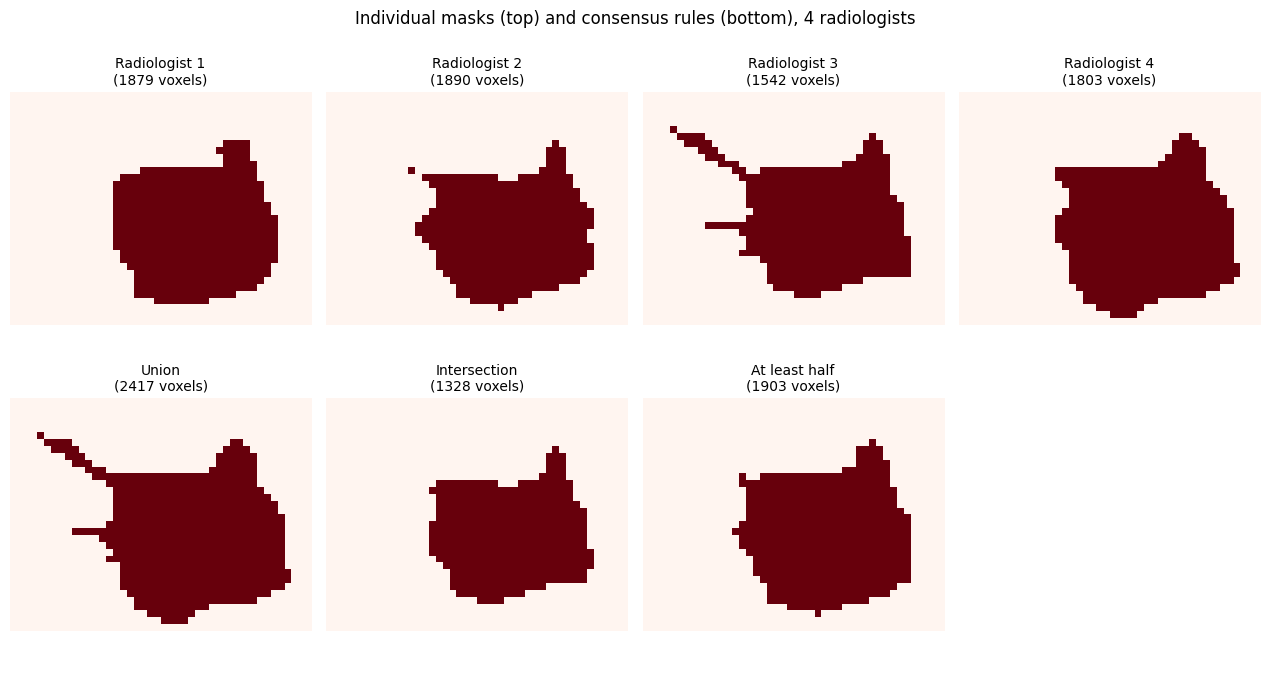

In [20]:
# The mask of each radiologist and three consensus rules, on the first nodule with 2 to 4 annotations
example_scan, example_group = None, None
for scan in pl.query(pl.Scan):
    groups = [group for group in cluster_annotations_silent(scan) if 2 <= len(group) <= 4]
    if groups:
        example_scan, example_group = scan, groups[0]
        break
n = len(example_group)

# Every mask placed in the coordinates of the whole volume, then stacked (one layer per radiologist)
volume = example_scan.to_volume()
masks = []
for ann in example_group:
    full_mask = np.zeros(volume.shape, dtype=bool)
    full_mask[ann.bbox()] = ann.boolean_mask()
    masks.append(full_mask)
stack = np.stack(masks)

# The three rules
rules = {
    "Union": stack.any(axis=0),                           # drawn by at least one radiologist
    "Intersection": stack.all(axis=0),                    # drawn by every radiologist
    "At least half": stack.mean(axis=0) >= 0.5,           # the consensus used in this project (as in pylidc)
}

# A box that contains every mask, and its central axial slice
boxes = [ann.bbox() for ann in example_group]
common_box = tuple(slice(min(b[axis].start for b in boxes), max(b[axis].stop for b in boxes)) for axis in range(3))
middle = stack[0][common_box].shape[2] // 2

# Top row: the mask of each radiologist. Bottom row: the three rules.
n_cols = max(n, 3)
fig, axes = plt.subplots(2, n_cols, figsize=(3.2 * n_cols, 7))
for i, mask in enumerate(masks):
    axes[0, i].imshow(mask[common_box][:, :, middle], cmap="Reds")
    axes[0, i].set_title(f"Radiologist {i + 1}\n({mask.sum()} voxels)", fontsize=10)
for j, (name, mask) in enumerate(rules.items()):
    axes[1, j].imshow(mask[common_box][:, :, middle], cmap="Reds")
    axes[1, j].set_title(f"{name}\n({mask.sum()} voxels)", fontsize=10)
for axis in axes.ravel():
    axis.axis("off")
plt.suptitle(f"Individual masks (top) and consensus rules (bottom), {n} radiologists", fontsize=12)
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    Conclusion
  </h3>

  <p>
    The individual masks (top row) show that the four radiologists disagree on the contours even for the same physical nodule, each draws a different shape in extent and form. The counts confirm this: individual radiologists produce 1542 to 1890 voxels, the union 2417, the intersection 1328 and the rule of at least half 1903, close to the largest individual mask. The choice of consensus rule therefore has a direct impact on the final mask volume, and consequently on any radiomic feature derived from its interior.
  </p>

  <p>
    <strong>The decision on the threshold is the critical part.</strong> The literature default is <strong>at least half of the radiologists (50% or more)</strong>, which is also the <code>pylidc</code> default: the <code>consensus</code> function with <code>clevel=0.5</code> marks a voxel as positive when at least half of the radiologists marked it (Carrazza et al., 2016). This is the rule adopted in this project: a voxel is positive when 2 or more of 4 radiologists marked it, 2 or more of 3, or either of 2.
  </p>

  <p>
    <strong>The alternative is the union</strong>, which maximises recall by including any voxel marked by at least one radiologist. The foundational study by Ross et al. (2007) explicitly compared union, intersection and STAPLE on 41 LIDC exams and concluded that <em>"using the union as the consensus scheme produced the greatest number of nodule-positive voxels while using the intersection produced the fewest"</em>. This means the union is the correct choice when the goal is to maximise sensitivity, for example, in detection tasks where missing a nodule is worse than including adjacent tissue. The intersection, by contrast, is the most conservative and can produce fragmented or empty masks when the contours disagree a lot.
  </p>

  <p>
    For malignancy classification, the rule of at least half is the correct compromise: it does not inflate the volume like the union (which includes perinodular tissue marked by a single radiologist) nor reduce it excessively like the intersection (which can eliminate regions of partial consensus). It stays close to the size of the individual masks (1903 voxels here, against 1542 to 1890), which is desirable for keeping comparability with features extracted from individual annotations.
  </p>

  <p>
    <strong>Note:</strong> for nodules with only 1 annotation, which are ~29% of the dataset, as seen in the coverage section, there is no consensus to apply. The mask is that of the single radiologist, used as is.
  </p>

</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Individual LIDC Ratings (agreement between radiologists)
  </h3>
  <p>
    Saves every individual LIDC malignancy rating, grouped by nodule, to measure agreement between radiologists. The agreement between two radiologists is the realistic ceiling of any model trained on their ratings. Nodules are grouped with the default pylidc clustering; the groups with more than four annotations are left out of this specific analysis.
  </p>
</div>

In [21]:
# Individual ratings of each radiologist, used in notebook 06 for the agreement between radiologists
if READER_RATINGS_FILE.exists():
    print("already on disk:", READER_RATINGS_FILE)
else:
    save_lidc_reader_ratings()

already on disk: /home/anasofia/labiacd/mass_detect/data/patches_0.6mm/lidc_reader_ratings.csv


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    Relevant differences LIDC IDRI vs. LNDb
  </h3>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Structural differences
  </h3>

  <table style="width: 100%; border-collapse: collapse; color: #f0f0f0;">
    <thead>
      <tr style="background-color: #c25719; color: #ffffff;">
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Aspect</th>
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">LIDC IDRI</th>
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">LNDb</th>
      </tr>
    </thead>
    <tbody>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><strong>Number of scans</strong></td>
        <td style="padding: 8px; border: 1px solid #444;">1018 CT series</td>
        <td style="padding: 8px; border: 1px solid #444;">294 series</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><strong>Number of institutions</strong></td>
        <td style="padding: 8px; border: 1px solid #444;">7</td>
        <td style="padding: 8px; border: 1px solid #444;">1 (CHUSJ, Porto)</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><strong>Methodology</strong></td>
        <td style="padding: 8px; border: 1px solid #444;">4 radiologists, 2 phases (blinded + unblinded)</td>
        <td style="padding: 8px; border: 1px solid #444;">5 radiologists, single blind</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><strong>Radiologist identity</strong></td>
        <td style="padding: 8px; border: 1px solid #444;">Anonymous, not traceable across scans</td>
        <td style="padding: 8px; border: 1px solid #444;">Traceable (consistent R1 to R5)</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><strong>Image format</strong></td>
        <td style="padding: 8px; border: 1px solid #444;">DICOM (.dcm) per slice</td>
        <td style="padding: 8px; border: 1px solid #444;">MetaImage (.mhd/.raw)</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><strong>Annotation format</strong></td>
        <td style="padding: 8px; border: 1px solid #444;">XML (<code>LidcReadMessage</code>) with per slice contours</td>
        <td style="padding: 8px; border: 1px solid #444;">CSV with 3D centre coordinates + volume</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><strong>Segmentation</strong></td>
        <td style="padding: 8px; border: 1px solid #444;">2D contours per slice (needs reconstruction)</td>
        <td style="padding: 8px; border: 1px solid #444;">Precomputed 3D mask</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><strong>Nodule volume</strong></td>
        <td style="padding: 8px; border: 1px solid #444;">Computed from the contour</td>
        <td style="padding: 8px; border: 1px solid #444;">Provided directly (in mm³)</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><strong>Diameter</strong></td>
        <td style="padding: 8px; border: 1px solid #444;">Computed (<code>annotation.diameter</code>)</td>
        <td style="padding: 8px; border: 1px solid #444;">Computed by <code>nodEqDiam</code> from the volume</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><strong>Subjective characteristics</strong></td>
        <td style="padding: 8px; border: 1px solid #444;">9 (subtlety, internalStructure, calcification, sphericity, margin, lobulation, spiculation, texture, malignancy)</td>
        <td style="padding: 8px; border: 1px solid #444;">The same 9 (texture in trainNodules.csv, the other 8 in chars_trainNodules.csv)</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><strong>Training set</strong></td>
        <td style="padding: 8px; border: 1px solid #444;">No official split</td>
        <td style="padding: 8px; border: 1px solid #444;">Official <code>train</code>/<code>test</code> split</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><strong>Acquisition</strong></td>
        <td style="padding: 8px; border: 1px solid #444;">Very heterogeneous (7 institutions, several scanners)</td>
        <td style="padding: 8px; border: 1px solid #444;">Homogeneous (1 institution)</td>
      </tr>
    </tbody>
  </table>

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 25px;">
    Implications for the pipeline
  </h3>

  <ol style="padding-left: 20px;">
    <li style="margin-bottom: 8px;"><strong>Label distribution is per radiologist, not per nodule.</strong> If a nodule has 4 annotations and 3 radiologists gave malignancy = 2 and 1 gave = 3, the "official" row does not exist, we have to decide how to aggregate (mean, median, majority, or keep the 4 rows separate as in LNDb).</li>
    <li style="margin-bottom: 8px;"><strong>The mask is 3D but sparse.</strong> In LNDb the mask is a dense binary volume. In LIDC, <code>ann.boolean_mask()</code> returns a mask within the bounding box, the pipeline has to handle both.</li>
    <li style="margin-bottom: 8px;"><strong>Contours have to be merged.</strong> If we want a "consensus" mask (as in LNDb, where there is one mask per nodule), we have to apply <code>pl.utils.consensus()</code> or a majority rule.</li>
    <li style="margin-bottom: 8px;"><strong>There is no stable <code>RadID</code>.</strong> It will not be possible to use the radiologist as a feature.</li>
    <li style="margin-bottom: 8px;"><strong>Duplicate XML files.</strong> The official package contains, for each CT series, a CT XML (<code>LidcReadMessage</code>) and often a chest radiograph XML (<code>IdriReadMessage</code>). <code>pylidc</code> <strong>only processes the CT XMLs</strong>.</li>
  </ol>

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 25px;">
    Caution
  </h3>

  <p>
    To access the volume, the DICOM images must be on disk and the <code>pylidcrc</code> configured with the correct path. In LNDb, <code>utils.py</code> reads the <code>.mhd</code> directly. Furthermore, unlike LNDb (which provides precomputed volumes in MetaImage), LIDC IDRI stores the contours as sequences of points <code>(x, y, z)</code> per slice. The volume has to be reconstructed.
  </p>

  <p>
    Each radiologist marked lesions in three categories: <em>nodule ≥ 3 mm</em>, <em>nodule &lt; 3 mm</em>, and <em>non nodule ≥ 3 mm</em>. Only nodules ≥ 3 mm have 3D contours and the 9 subjective characteristics.
  </p>

</div>